# Loading the KiDS-Legacy Gower Street mocks

This notebook reads the two data products of our KiDS-Legacy mock suite and shows what each one holds.

- The **galaxy catalogues** hold every simulated source galaxy of one mock, for 8 Gower Street N-body
  cosmologies (sims 193 to 200).
- The **processed mocks** hold the two summaries the inference uses: pseudo-$C_\ell$ bandpowers and
  smoothed E-mode convergence maps, for 48 Gower Street cosmologies.

The middle of the notebook runs one catalogue through the library calls of
`master_kids_legacy_simulator.py`, from galaxy ellipticities to bandpowers and maps, and compares the
result with the stored products.

All mocks share one forward model: Gower Street matter shells at HEALPix nside 1024, NLA-M intrinsic
alignments, a galaxy bias per tomographic bin for source clustering, the KiDS-Legacy footprint, and the
variable-depth shape-noise model. Run the notebook in the `glass` environment. The catalogue section
needs about 10 GB of memory and a few minutes, mostly for the spherical-harmonic transforms.

The first cell holds the paths and the choices the whole notebook shares. Set `DATA_DIR` to the folder
that holds the two data directories.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = Path("/data/alex/kids_share")
CATALOGUE_DIR = DATA_DIR / "gower_cats_nla_m_vdq_n8"
MOCK_DIR = DATA_DIR / "gower_mocks_nla_m_vdq_bgp"

SIM_ID = 193
MASK_IDX = 0
MAP_VARIANT = "E_sc8_fwhm4_lmin56_lcut1400"
COSMO_PARAMS = ["omega_m", "sigma_8", "w0", "h", "ns", "ombh2", "mnu", "a_ia", "b_ia",
                "b_g_bin1", "b_g_bin2", "b_g_bin3", "b_g_bin4", "b_g_bin5", "b_g_bin6"]

## The galaxy catalogue

Each catalogue file is one mock: all source galaxies of one cosmology seen through the KiDS-Legacy
footprint. The file name `catalogue_{sim}_out0_rot0_{k}.h5` gives the Gower Street simulation id and a
realisation index `k` from 0 to 3. The four realisations of one simulation are independent mocks of the
same cosmology on the same footprint, and they are all processed in the same way.

The `catalogue` group holds one entry per galaxy: `RA` and `DEC` in degrees, the true redshift `Z_TRUE`,
the tomographic bin `ZBIN` (0 to 5), and the observed ellipticities `E1` and `E2`. The ellipticities
include the cosmic shear, the intrinsic alignments, the shape noise and the shear biases. The
`cosmo_dict` group holds the parameters of the mock, and the file attributes record how the simulator
processed it. The next cell reads all three.

In [2]:
import h5py
import numpy as np

catalogue_path = CATALOGUE_DIR / "catalogues" / f"catalogue_{SIM_ID}_out0_rot0_{MASK_IDX}.h5"
with h5py.File(catalogue_path, "r") as f:
    catalogue = {column: f["catalogue"][column][:] for column in f["catalogue"]}
    cosmology = {name: f["cosmo_dict"][name][()] for name in f["cosmo_dict"]}
    attrs = dict(f.attrs)

print(f"{len(catalogue['RA']):,} galaxies, columns {list(catalogue)}")
for name, value in cosmology.items():
    print(f"  {name:16s} {value.decode() if isinstance(value, bytes) else f'{value:.4f}'}")
for name in ["nside", "nside_out", "shear_normalization", "m_bias_for_shear", "galaxy_bias"]:
    print(f"  attr {name:20s} {attrs[name]}")

30,445,797 galaxies, columns ['DEC', 'E1', 'E2', 'RA', 'ZBIN', 'Z_TRUE']
  a_ia             5.3292
  b_g_bin1         0.7962
  b_g_bin2         1.2199
  b_g_bin3         0.8320
  b_g_bin4         1.3098
  b_g_bin5         1.4166
  b_g_bin6         1.4378
  b_ia             0.3099
  galaxy_bias_eff  1.1400
  h                0.6917
  ia_model         nla_m
  mnu              0.0685
  ns               0.9644
  ombh2            0.0224
  omega_m          0.4610
  sigma_8          0.4755
  vd_code          3.0000
  w0               -1.0042
  attr nside                1024
  attr nside_out            512
  attr shear_normalization  counts
  attr m_bias_for_shear     [-0.022869 -0.015966 -0.011331  0.01987   0.029506  0.044535]
  attr galaxy_bias          [0.79620509 1.2198538  0.83204755 1.30979865 1.41660731 1.43783156]


The parameters use the Gower Street names. `omega_m` is the total matter density, `sigma_8` the
amplitude of matter fluctuations, `w0` the dark-energy equation of state, `ns` the spectral index,
`ombh2` the physical baryon density and `mnu` the neutrino mass sum in eV. `a_ia` and `b_ia` are the
NLA-M intrinsic-alignment amplitude and its halo-mass slope. `b_g_bin1` to `b_g_bin6` are the galaxy
biases of the six bins, and `galaxy_bias_eff` is their density-weighted mean. `vd_code = 3` marks the
variable-depth noise model. Two attributes set the resolutions used below: `nside = 1024` for every
HEALPix map made from the catalogue, and `nside_out = 512` for the stored map patches.
`m_bias_for_shear` is the multiplicative shear bias per bin that the estimator divides out.

The next figure shows where the galaxies are and how their true redshifts spread over the six bins.

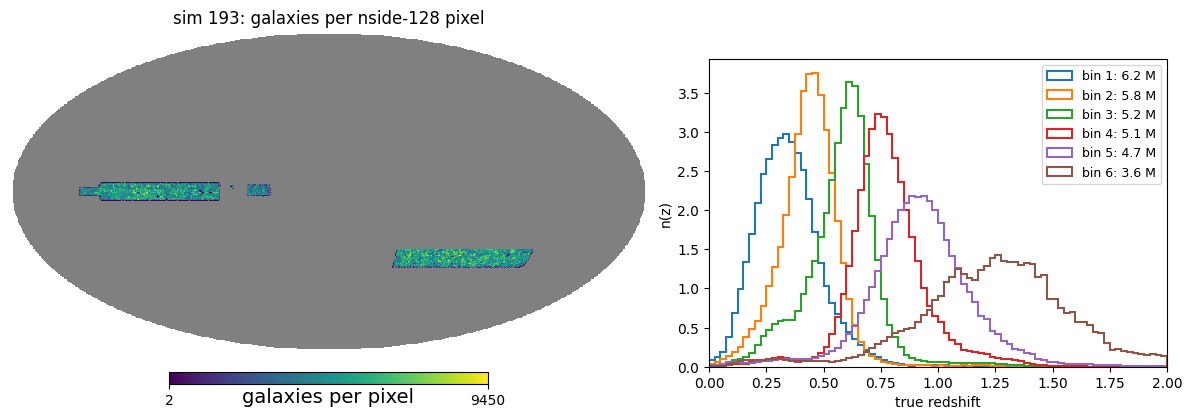

In [3]:
import healpy as hp
import matplotlib.pyplot as plt

counts = np.bincount(hp.ang2pix(128, catalogue["RA"], catalogue["DEC"], lonlat=True),
                     minlength=hp.nside2npix(128)).astype(float)
counts[counts == 0] = hp.UNSEEN

fig = plt.figure(figsize=(13, 4))
hp.mollview(counts, fig=fig.number, sub=(1, 2, 1), rot=(95, 0, 0), unit="galaxies per pixel",
            title=f"sim {SIM_ID}: galaxies per nside-128 pixel")
ax = fig.add_subplot(1, 2, 2)
z_edges = np.linspace(0.0, 2.0, 81)
for tomo_bin in range(6):
    in_bin = catalogue["ZBIN"] == tomo_bin
    ax.hist(catalogue["Z_TRUE"][in_bin][::20], bins=z_edges, density=True, histtype="step",
            lw=1.5, label=f"bin {tomo_bin + 1}: {in_bin.sum() / 1e6:.1f} M")
ax.set(xlabel="true redshift", ylabel="n(z)", xlim=(0, 2))
ax.legend(fontsize=9)
plt.show()

The footprint is the two KiDS-Legacy patches, a northern strip around RA 180 degrees and a southern
strip around RA 0. The pixel-to-pixel structure inside them is the variable depth and the galaxy
clustering. The redshift distributions overlap because the bins are assigned from photometric
redshifts, while `Z_TRUE` is the true redshift.

## From ellipticities to pseudo-$C_\ell$ bandpowers

The simulator turns a catalogue into bandpowers in three steps.

1. `make_alm_shear_convergence` bins the galaxies of each tomographic bin into HEALPix pixels at
   nside 1024. It subtracts the mean ellipticity, sums the ellipticities in each pixel, divides by
   the number of galaxies in the pixel (`normalization="counts"`) and by $1 + m$. A spin-2 transform
   to $\ell_\mathrm{max} = 2048$ gives the E and B alms. It repeats this for a copy of the catalogue
   with every ellipticity turned by a random angle, which keeps the shape noise and removes the shear.
2. `denoise_shear_cls` forms the 21 auto- and cross-spectra of the six bins. It subtracts the
   noise power, measured on the randomised copy, from the auto-spectra.
3. `compute_cl_bandpowers` averages $\ell(\ell+1)C_\ell/2\pi$ of the EE spectra in 8 logarithmic bands
   between $\ell = 56$ and $1500$.

The spectra stay mixed by the survey mask (pseudo-$C_\ell$), because the simulation-based inference
compares like with like and never unmixes them. The next cell runs the three steps, which take about
half a minute.

In [4]:
from src.cosmology.manip_cls import compute_cl_bandpowers, denoise_shear_cls
from src.cosmology.map_shears import make_alm_shear_convergence
from src.KiDS.simulation_config import lower_lscale, nbands, nbins, upper_lscale

nside = int(attrs["nside"])
lmax = 2 * nside
m_bias = attrs["m_bias_for_shear"]
rng = np.random.default_rng(0)

alm, alm_random = make_alm_shear_convergence(catalogue, m_bias, nbins, nside, lmax,
                                             normalization="counts", rng=rng)
mixed_cls = denoise_shear_cls(nbins, alm, alm_random, lmax)
ell_bands, bandpowers = compute_cl_bandpowers(mixed_cls[:, :, :, lower_lscale:upper_lscale + 1],
                                              nbins, lower_lscale, upper_lscale, nbands)
print(f"nside {nside}, lmax {lmax}, bands between ell {lower_lscale} and {upper_lscale}")
print("bandpowers", bandpowers.shape, "band centres", np.round(ell_bands))

nside 1024, lmax 2048, bands between ell 56 and 1500
bandpowers (21, 8) band centres [  70.  106.  160.  241.  364.  549.  827. 1248.]


The simulator saved the products of this catalogue in the matching `output_{sim}_out0_rot0_{k}.h5` file. The next figure compares our bandpowers with the stored ones for all 21 bin pairs. The 21
rows of the `(21, 8)` array run over the pairs (1,1), (2,1), (2,2), (3,1), and so on.

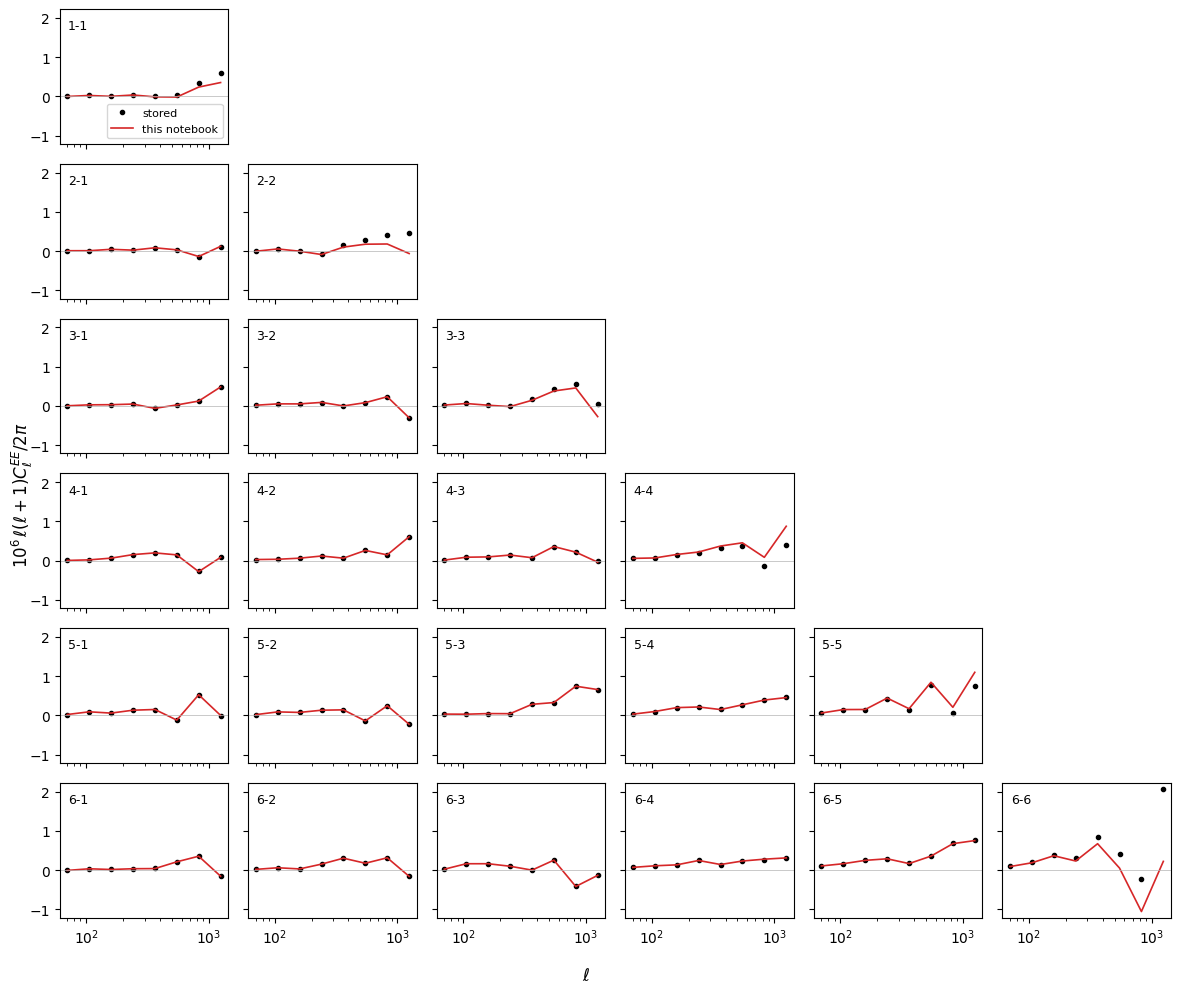

In [5]:
output_path = CATALOGUE_DIR / f"output_{SIM_ID}_out0_rot0_{MASK_IDX}.h5"
with h5py.File(output_path, "r") as f:
    stored_bandpowers = f["cls_results/full/mixed_bandpowers"][:]
    stored_ell = f["cls_results/full/bandpower_ls"][:]

bin_pairs = [(i, j) for i in range(nbins) for j in range(i + 1)]
fig, axes = plt.subplots(nbins, nbins, figsize=(12, 10), sharex=True, sharey=True)
for row, (i, j) in enumerate(bin_pairs):
    ax = axes[i, j]
    ax.plot(stored_ell, 1e6 * stored_bandpowers[row], "ko", ms=3, label="stored")
    ax.plot(ell_bands, 1e6 * bandpowers[row], "C3-", lw=1.2, label="this notebook")
    ax.axhline(0, color="0.7", lw=0.5)
    ax.text(0.05, 0.85, f"{i + 1}-{j + 1}", transform=ax.transAxes, fontsize=9)
for i in range(nbins):
    for j in range(i + 1, nbins):
        axes[i, j].set_visible(False)
axes[0, 0].set_xscale("log")
axes[0, 0].legend(fontsize=8, loc="lower right")
fig.supxlabel(r"$\ell$")
fig.supylabel(r"$10^6\,\ell(\ell+1)C_\ell^{EE}/2\pi$")
fig.tight_layout()
plt.show()

The signal grows with redshift, from the 1-1 pair to the 6-6 pair. The cross-spectra of the replay
match the stored ones. The auto-spectra differ at high $\ell$, because the noise subtraction uses a
fresh random rotation of the ellipticities each time. Two runs of this cell with different seeds differ
by as much. The difference is a constant offset in $C_\ell$, so it grows as $\ell^2$ in these units.

## From ellipticities to E-mode convergence maps

The maps follow a second branch with three changes.

1. The pixel sums are divided by the galaxy count smoothed with an 8 arcmin Gaussian
   (`normalization="smoothed_counts"`) instead of the raw count. The map noise then no longer follows
   the clustering of the source galaxies. This is the `sc8` in the map names.
2. `filter_EB_alms_and_make_maps` multiplies the alms by a 4 arcmin Gaussian beam, keeps
   $56 \le \ell \le 1400$, tapers to zero at $\ell = 1500$ and synthesises the E map at nside 512
   (pixels of 6.9 arcmin). The E-mode alms of the shear equal the convergence alms up to the factor
   $\sqrt{(\ell+2)(\ell-1)/\ell(\ell+1)}$, which is within 0.03 % of 1 for $\ell \ge 56$. The E map is
   therefore the Kaiser-Squires convergence map $\kappa_E$.
3. `get_patch_values` reads the nside-512 map onto one Cartesian grid per KiDS-Legacy patch, with one
   grid cell per HEALPix pixel width. Each patch is an array of shape `(6, n_lat, n_lon)`.

The stored mocks also hold a second variant, `E_sc8_fwhm8_lmin56_lcut1024`, with an 8 arcmin beam and
$\ell \le 1024$. The next cell makes the 4 arcmin variant and reads the stored one.

In [6]:
from src.cosmology.map_shears import filter_EB_alms_and_make_maps
from src.cosmology.pixelise_maps import get_patch_values
from src.KiDS.simulation_config import named_patches, patches

nside_out = int(attrs["nside_out"])
alm_sc8, _ = make_alm_shear_convergence(catalogue, m_bias, nbins, nside, lmax,
                                        normalization="smoothed_counts",
                                        smoothed_counts_fwhm_arcmin=8.0, rng=rng)
E_maps, _ = filter_EB_alms_and_make_maps(alm_sc8, nside_out=nside_out, fwhm_arcmin=4.0,
                                         lmin=56, lcut=1400)
E_patches = dict(zip(named_patches, get_patch_values(E_maps, patches, nside_out, 0)))

with h5py.File(output_path, "r") as f:
    stored_patches = {patch: f[f"pixelised_results/{MAP_VARIANT}/{patch}"][:].astype(float)
                      for patch in named_patches}
for patch in named_patches:
    residual = E_patches[patch] - stored_patches[patch]
    print(f"{patch}: shape {E_patches[patch].shape}, map rms {stored_patches[patch].std():.4f}, "
          f"residual rms / map rms {residual.std() / stored_patches[patch].std():.3f}")

south: shape (6, 97, 786), map rms 0.0237, residual rms / map rms 0.009
north: shape (6, 88, 979), map rms 0.0224, residual rms / map rms 0.008


The next figure shows the stored map of the highest-redshift bin in both patches, and our replay minus
the stored map on the same colour scale. Longitude is the patch longitude in degrees, as defined in
`named_patches`.

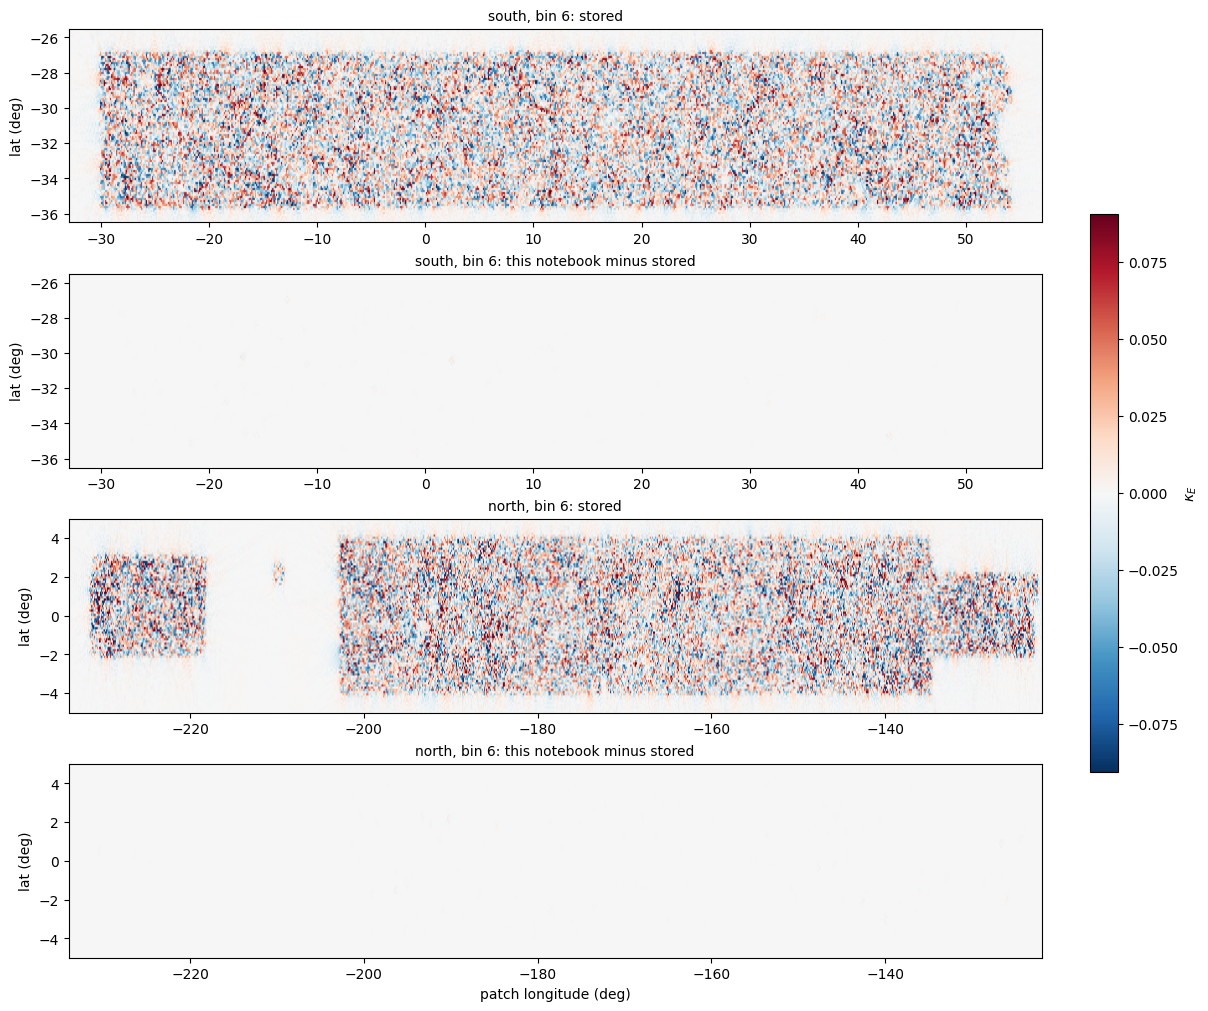

In [7]:
tomo_bin = 5
vmax = 3 * stored_patches["south"][tomo_bin].std()
fig, axes = plt.subplots(4, 1, figsize=(12, 10), layout="constrained")
for k, patch in enumerate(named_patches):
    lon_deg, lat_deg, width_deg, height_deg = named_patches[patch]
    extent = [lon_deg - width_deg / 2, lon_deg + width_deg / 2, lat_deg - height_deg / 2,
              lat_deg + height_deg / 2]
    for ax, image, label in [(axes[2 * k], stored_patches[patch][tomo_bin], "stored"),
                             (axes[2 * k + 1], E_patches[patch][tomo_bin] - stored_patches[patch][tomo_bin],
                              "this notebook minus stored")]:
        shown = ax.imshow(image, origin="lower", extent=extent, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                          aspect="auto")
        ax.set_title(f"{patch}, bin {tomo_bin + 1}: {label}", fontsize=10)
        ax.set_ylabel("lat (deg)")
axes[-1].set_xlabel("patch longitude (deg)")
fig.colorbar(shown, ax=axes, label=r"$\kappa_E$", shrink=0.6)
plt.show()

The convergence maps show the cosmic-shear signal on top of shape noise, which dominates pixel by
pixel. The replay matches the stored map to about 1 % of the map rms. The catalogue is saved in
float32 and the maps in float16, so a replay is close but not bit-identical.

## The processed mocks

The 960 files in `gower_mocks_nla_m_vdq_bgp` hold 20 independent mocks for each of 48 cosmologies. In a
file name `output_{sim}_out{o}_rot{r}_0.h5`, the indices `o` (0 to 3) and `r` (0 to 4) only label the
realisation. Each file holds:

- `cls_results/full/mixed_bandpowers`, shape `(21, 8)`, and the band centres `bandpower_ls`, shape `(8,)`;
- `cls_results/full/cls`, shape `(6, 6, 2, 2049)`, the noise-subtracted EE and BB pseudo-spectra per $\ell$;
- `pixelised_results/E_sc8_*/{north,south}`, the two map variants in float16, shapes `(6, 88, 979)` and
  `(6, 97, 786)`;
- `pixelised_results/noise_std_sc8_*`, the rms of a noise-only map per bin;
- `cosmo_dict`, the parameters, with the same names as in the catalogues.

The next cell reads the parameters of every file with `load_cosmo_params`, the reader our training code
uses. It keeps one row per cosmology.

In [8]:
import re
from src.ml.data.data_loading import load_cosmo_params

mock_paths = sorted(MOCK_DIR.glob("output_*.h5"))
sim_ids = np.array([int(re.search(r"output_(\d+)_", path.name).group(1)) for path in mock_paths])
first_path = {sim: path for sim, path in zip(sim_ids[::-1], mock_paths[::-1])}
cosmologies = np.array([load_cosmo_params(str(first_path[sim]), COSMO_PARAMS, as_torch=False,
                                          dtype=np.float64)[0] for sim in sorted(first_path)])
print(f"{len(mock_paths)} mocks, {len(first_path)} cosmologies, parameter table {cosmologies.shape}")

960 mocks, 48 cosmologies, parameter table (48, 15)


The next figure shows the 48 cosmologies in the $\Omega_\mathrm{m}$ to $\sigma_8$ plane, coloured by
$S_8 = \sigma_8 \sqrt{\Omega_\mathrm{m}/0.3}$. The ringed points also have catalogues.

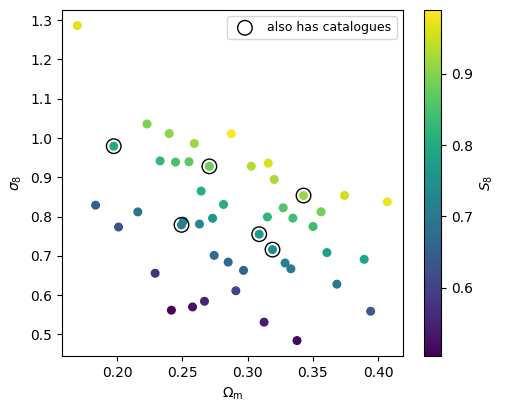

In [9]:
omega_m, sigma_8 = cosmologies[:, 0], cosmologies[:, 1]
s8 = sigma_8 * np.sqrt(omega_m / 0.3)
has_catalogue = np.isin(sorted(first_path), range(193, 201))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
points = ax.scatter(omega_m, sigma_8, c=s8, cmap="viridis", s=30)
ax.scatter(omega_m[has_catalogue], sigma_8[has_catalogue], s=110, facecolor="none", edgecolor="k",
           label="also has catalogues")
fig.colorbar(points, label=r"$S_8$")
ax.set(xlabel=r"$\Omega_\mathrm{m}$", ylabel=r"$\sigma_8$")
ax.legend(fontsize=9)
plt.show()

The 48 cosmologies cover $S_8$ from about 0.5 to 1.0. The next cell reads the bandpowers and maps of
every mock of three cosmologies, with low, middle and high $S_8$.

In [10]:
def read_mock(path, map_variant=MAP_VARIANT):
    with h5py.File(path, "r") as f:
        return {"bandpowers": f["cls_results/full/mixed_bandpowers"][:],
                "ell": f["cls_results/full/bandpower_ls"][:],
                "maps": {patch: f[f"pixelised_results/{map_variant}/{patch}"][:].astype(np.float32)
                         for patch in ("north", "south")}}

sims_by_s8 = np.array(sorted(first_path))[np.argsort(s8)]
chosen_sims = [sims_by_s8[0], sims_by_s8[len(sims_by_s8) // 2], sims_by_s8[-1]]
mocks = {sim: [read_mock(path) for path in mock_paths if path.name.startswith(f"output_{sim}_")]
         for sim in chosen_sims}
s8_of = dict(zip(sorted(first_path), s8))
print({int(sim): f"S8 = {s8_of[sim]:.3f}, {len(mocks[sim])} mocks" for sim in chosen_sims})

{249: 'S8 = 0.504, 20 mocks', 219: 'S8 = 0.787, 20 mocks', 208: 'S8 = 0.989, 20 mocks'}


The 6-6 auto-spectrum of every mock of the three cosmologies, and the highest-redshift map of the
southern patch for the first mock of the lowest and highest $S_8$ cosmology.

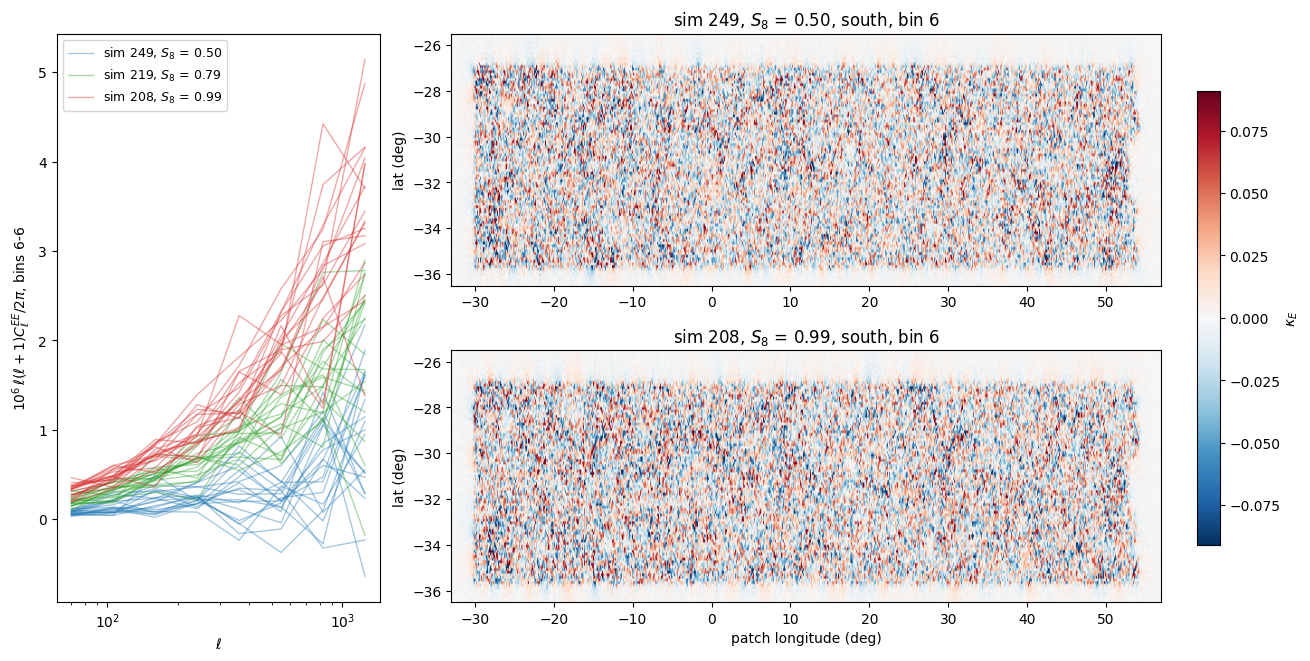

In [11]:
fig = plt.figure(figsize=(13, 6.5), layout="constrained")
grid = fig.add_gridspec(2, 2, width_ratios=[1, 2.2])
ax = fig.add_subplot(grid[:, 0])
for colour, sim in zip(["C0", "C2", "C3"], chosen_sims):
    for n, mock in enumerate(mocks[sim]):
        ax.plot(mock["ell"], 1e6 * mock["bandpowers"][-1], color=colour, alpha=0.4, lw=1,
                label=f"sim {sim}, $S_8$ = {s8_of[sim]:.2f}" if n == 0 else None)
ax.set(xscale="log", xlabel=r"$\ell$", ylabel=r"$10^6\,\ell(\ell+1)C_\ell^{EE}/2\pi$, bins 6-6")
ax.legend(fontsize=9)

lon_deg, lat_deg, width_deg, height_deg = named_patches["south"]
extent = [lon_deg - width_deg / 2, lon_deg + width_deg / 2, lat_deg - height_deg / 2, lat_deg + height_deg / 2]
vmax = 3 * mocks[chosen_sims[0]][0]["maps"]["south"][5].std()
for row, sim in enumerate([chosen_sims[0], chosen_sims[-1]]):
    ax = fig.add_subplot(grid[row, 1])
    shown = ax.imshow(mocks[sim][0]["maps"]["south"][5], origin="lower", extent=extent, cmap="RdBu_r",
                      vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set(title=f"sim {sim}, $S_8$ = {s8_of[sim]:.2f}, south, bin 6", ylabel="lat (deg)")
ax.set_xlabel("patch longitude (deg)")
fig.colorbar(shown, ax=fig.axes[1:], label=r"$\kappa_E$", shrink=0.8)
plt.show()

The bandpower amplitude rises with $S_8$, and the spread within one cosmology is the scatter between
independent mocks. In the maps, shape noise dominates each pixel, and the cosmology shows up in the
statistics of the field.